# code_043 · Dependencies and confounding patterns

**Book:** section 9.2. A self-contained exploration laboratory using invented building, load and sensor records. Prerequisites: arrays/tables and Chapter 8's case, timing and schema contracts. Restart and run all cells; all imports, helpers and generated inputs are here. Ordinary execution needs no files, network, keys, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_09_GUIDE.md), [execution evidence](../CHAPTER_09_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_043).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow one minute to run and 30–60 minutes to interpret. These scoped concept experiments disclose data/task controls rather than claim exhaustive estimator API coverage. Plots and construction identities are exploratory diagnostics, not independent predictive evidence. Only the hypothesis laboratory fits competing predictors, selects on development buildings and opens a protected final set after freezing its rule. All evidence is synthetic, with no structural-safety, population-calibration or causal claim.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=943;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 943


<a id="conditional"></a>
## A pooled slope can reverse within groups

Create 120 steel members ages 5–25 and 120 concrete members ages 40–60 years. Within each group, measured deflection y=intercept-.02*age+noise sd .04 mm, with intercept 1 for steel and 4 for concrete. Thus each group's age slope is negative while older ages are concentrated in the higher-intercept material group. This is a constructed association example, not a causal aging law. Age ranges do not overlap: conditional comparisons at common age are unsupported without additional assumptions.

Use ordinary least-squares slopes solely to summarize exploratory relationships. Units: age in years, deflection mm, slope mm/year. No held-out predictive claim is made. Material might stand for different geometry, loading or selection in real records; conditioning is not automatically causal adjustment.


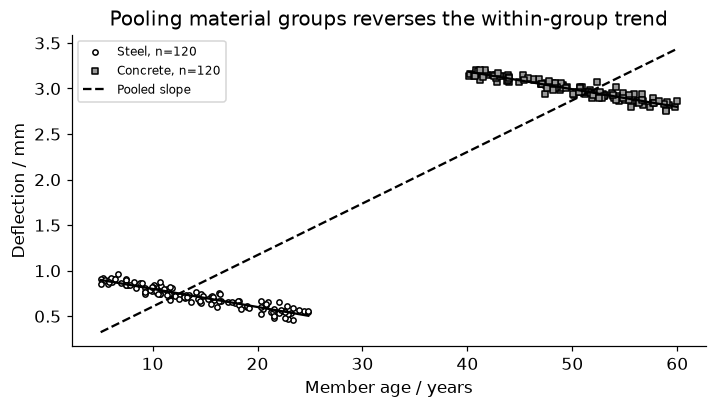

In [2]:
N=240;g=np.repeat([0,1],120);age=np.r_[rng.uniform(5,25,120),rng.uniform(40,60,120)];y=np.where(g==0,1.,4.)-.02*age+rng.normal(0,.04,N)
def slope(x,z):return float(np.linalg.lstsq(np.column_stack([np.ones(len(x)),x]),z,rcond=None)[0][1])
pooled=slope(age,y);within={str(k):slope(age[g==k],y[g==k]) for k in [0,1]}
assert pooled>0 and all(v<0 for v in within.values())
fig,ax=plt.subplots(figsize=(6.4,3.6))
for k,marker,name in [(0,'o','Steel'),(1,'s','Concrete')]:
 ix=g==k;ax.scatter(age[ix],y[ix],s=12,facecolors='white' if k==0 else '.6',edgecolors='black',marker=marker,label=f'{name}, n={ix.sum()}');xx=np.array([age[ix].min(),age[ix].max()]);ax.plot(xx,y[ix].mean()+within[str(k)]*(xx-age[ix].mean()),color='black')
xx=np.array([age.min(),age.max()]);ax.plot(xx,y.mean()+pooled*(xx-age.mean()),'k--',label='Pooled slope');ax.set(xlabel='Member age / years',ylabel='Deflection / mm',title='Pooling material groups reverses the within-group trend');ax.legend(fontsize=8);plt.show()
RESULTS['pooled_age_slope_mm_per_year']=pooled;RESULTS['within_material_slopes_mm_per_year']=within


<a id="decomposition"></a>
## Separate within-group from between-group covariance

Use population-normalized sample moments here (divide by N) so the decomposition is exact for the observed table: Cov(X,Y)=mean_group Cov(X,Y|G)+Cov(group means). Weights are observed group proportions, not equal group weights by default. This arithmetic identity explains the pooled pattern without identifying which variable causes which. Duplicate age in days is redundant information even though its coefficient scale differs.


In [3]:
def covariance(x,z):return float(np.mean((x-x.mean())*(z-z.mean())))
weights=np.array([(g==k).mean() for k in [0,1]]);means_x=np.array([age[g==k].mean() for k in [0,1]]);means_y=np.array([y[g==k].mean() for k in [0,1]])
within_cov=float(sum(weights[k]*covariance(age[g==k],y[g==k]) for k in [0,1]));between_cov=float(np.sum(weights*(means_x-age.mean())*(means_y-y.mean())));total=covariance(age,y)
assert np.isclose(total,within_cov+between_cov) and within_cov<0 and between_cov>0
age_days=age*365.25;assert np.isclose(np.corrcoef(age,age_days)[0,1],1.)
assert np.linalg.matrix_rank(np.column_stack([np.ones(N),age,age_days]))==2
RESULTS['covariance_decomposition_year_mm']={'total':total,'within':within_cov,'between':between_cov}


<a id="nonlinear"></a>
## Near-zero linear correlation need not mean independence

A separate symmetric grid x in [-1,1] and deterministic z=x² has zero sample linear covariance, yet z is completely determined by x. Spearman rank correlation detects monotone order, not every nonlinear relationship; the U shape also has zero rank correlation on this symmetric fixture. Add a monotone exp(x) example to distinguish the metrics. No p values or causal conclusions are needed to inspect these mechanisms.


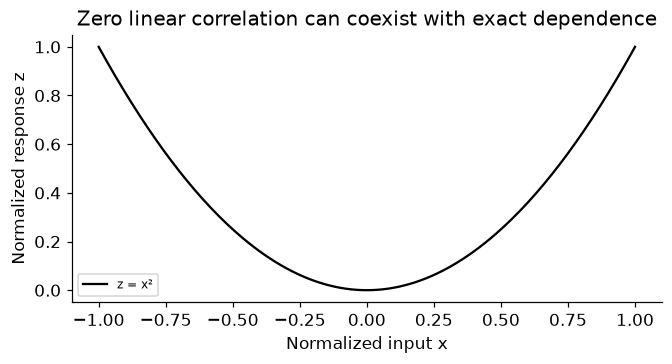

In [4]:
from scipy.stats import spearmanr
x=np.arange(-100,101,dtype=float)/100;z=x*x
linear=float(np.corrcoef(x,z)[0,1]);rank=float(spearmanr(x,z).statistic);monotone=float(spearmanr(x,np.exp(x)).statistic)
assert abs(linear)<1e-12 and abs(rank)<.02 and np.isclose(monotone,1)
assert np.allclose(z,x*x) and not np.allclose(z,z.mean())
fig,ax=plt.subplots(figsize=(6,3.2));ax.plot(x,z,'k-',label='z = x²');ax.set(xlabel='Normalized input x',ylabel='Normalized response z',title='Zero linear correlation can coexist with exact dependence');ax.legend(fontsize=8);plt.show()
RESULTS['symmetric_nonlinear_correlations']={'Pearson':linear,'Spearman':rank,'monotone_exp_Spearman':monotone}


<a id="exercises"></a>
## Exercises and hints

1. Add age overlap between materials and compare pooled and conditional summaries again.
2. Change group proportions without changing conditional mechanisms; predict which covariance term changes.
3. Introduce a shared measurement offset and ask whether conditioning on recorded material is sufficient.
4. Add label-derived features and explain why excellent association can reflect information leakage.

**Hints:** retain units, group sizes and observed support. Conditioning on a mediator or selection variable can alter a causal question; this lab makes descriptive claims only. Rank correlation is not a general nonlinear-dependence detector. See official [Spearman documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html); the executed SciPy version is 1.17.1.


In [5]:
summary={'example_id':'code_043','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['pooled versus material-conditional associations', 'covariance decomposition with group context', 'nonlinear dependence with near-zero linear correlation', 'rank correlation and redundant features', 'association is not intervention'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["pooled versus material-conditional associations", "covariance decomposition with group context", "nonlinear dependence with near-zero linear correlation", "rank correlation and redundant features", "association is not intervention"], "elapsed_seconds": 0.126, "example_id": "code_043", "hardware": "Darwin arm64 CPU", "results": {"covariance_decomposition_year_mm": {"between": 20.242547676186305, "total": 19.62204149667501, "within": -0.6205061795112922}, "pooled_age_slope_mm_per_year": 0.05663738342305551, "symmetric_nonlinear_correlations": {"Pearson": -5.058306117529278e-17, "Spearman": 0.0, "monotone_exp_Spearman": 1.0}, "within_material_slopes_mm_per_year": {"0": -0.019868017919542364, "1": -0.01938975998886825}}, "seed": 943, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
